# Two probes, one grid: comparing a CIP and a 2D-S

> ## Nothing in this notebook is a measurement.
> **Both products are synthetic, invented in section 2 by a random-number generator, and every figure and
> statistic below is computed from them.** No measured file of any kind is read: the notebook runs
> on a fresh clone with nothing but the repository. Do not quote a number from this page, cite one
> of its figures, or read a finding into a ratio it draws.

**What this notebook is for.** A CIP and a 2D-S are different optical array probes: different
pixel size, different sample volume, different bin ladder. Once both are processed into the same
`sizeDist` product layout, one helper can put them on a common size grid and time axis and compare
them. That is what this notebook shows, step by step.

The method has four traps, and they are the substance:

1. the two grids **share no edge**, so a straddling bin is apportioned by width, and the
   uncertainty that creates is *wider* than the Poisson one wherever the counts are good;
2. an empty second is a **zero**, not a gap: reading it as missing inflates each probe's mean by a
   different factor and manufactures a ratio out of nothing;
3. a **raw Pearson on 1 Hz counts** measures the heavy tail, not the cloud;
4. window averaging works, but only **with a density gate**, and the gate is expensive.

Everything below calls `arrayprobe.tools.probe_comparison`, the same functions you would call on
your own products.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Related:** [02_probe_overlap_check](02_probe_overlap_check.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

In [1]:
"""Set-up, and the banner in the output as well as the prose."""
# Launch guard: the notebook expects the repository root as its working directory.
from pathlib import Path

if not Path("examples").is_dir():
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/7_analysis_and_outputs/), so run "
        "`%cd ../..` in a new cell, then run this cell again."
    )

import tempfile

import netCDF4
import numpy as np

from arrayprobe.tools import probe_comparison as pc
from arrayprobe_uiops.sizedist_tables import probe_defaults

print("=" * 78)
print("SYNTHETIC DEMONSTRATION -- every number below is invented, none is measured.")
print("=" * 78)

# One scratch directory, created here and named in every later cell. Nothing is written
# anywhere in the repository; re-running the notebook makes a fresh one.
demo_dir = Path(tempfile.mkdtemp(prefix="cip_vs_2ds_demo_"))
rng = np.random.default_rng(20260918)
print(f"\nscratch directory: <system temp>/{demo_dir.name}")

SYNTHETIC DEMONSTRATION -- every number below is invented, none is measured.

scratch directory: <system temp>/cip_vs_2ds_demo_zxlbs3pp


## 1. Why a common grid is needed at all

Each probe is processed onto its own bin ladder, and the two ladders do not line up.

- the **CIP** ladder is read from the package's probe tables
  (`arrayprobe_uiops.sizedist_tables.probe_defaults`). A campaign the table does not list, such as
  the made-up `"my_campaign"` used here, takes `sizeDist.m`'s default (`otherwise`) branch, whose
  CIP case is the 19-bin non-uniform literal table
  (`UIOPS-v3.5/joefinlon-UIOPS-039be82/sizeDist.m:522-531`): 50, 100, 150, … 400, 475, 550, …,
  coarse at the small end and coarser still above 400 µm.
- the **2D-S** ladder is a fine uniform one, 128 bins of 10 µm from 5 µm, written out in the cell
  below: a ladder of the kind a 10 µm-pixel probe is processed onto.

The comparison grid is `probe_comparison.COMMON_EDGES_UM`: 55–105 µm, then 100 µm bins at 105,
205, … 1005. Every edge is a 2D-S ladder edge, so the 2D-S side is a **pure sum**: every one of its
bins is wholly inside a common bin or wholly outside it, and its apportioning weights are 0 or 1 to
float precision. The CIP shares **no** edge with it, so a straddling CIP bin is split by the
fraction of its width inside each common bin, assuming dN/dD is flat across that bin. That
assumption is the whole of the apportioning uncertainty, and section 6 measures what it costs.

In [2]:
"""Both ladders, read from the package, and what the common grid does to each."""
CIP_EDGES_UM = probe_defaults("my_campaign", "CIP", version="3.5").kk() * 1000.0
TWODS_EDGES_UM = 5.0 + 10.0 * np.arange(129)          # 128 bins of 10 um from 5 um
COMMON = pc.COMMON_EDGES_UM

print(f"2D-S ladder             : {len(TWODS_EDGES_UM) - 1:3d} bins, "
      f"{TWODS_EDGES_UM[0]:.0f}-{TWODS_EDGES_UM[-1]:.0f} um, uniform 10 um")
print(f"CIP ladder              : {len(CIP_EDGES_UM) - 1:3d} bins, "
      f"{CIP_EDGES_UM[0]:.0f}-{CIP_EDGES_UM[-1]:.0f} um, non-uniform")
print(f"   first CIP edges      : {CIP_EDGES_UM[:9].astype(int)}")
print(f"common grid             : {COMMON.astype(int)}")

w_2ds = pc.rebin_weights(TWODS_EDGES_UM[:-1], TWODS_EDGES_UM[1:], COMMON)
w_cip = pc.rebin_weights(CIP_EDGES_UM[:-1], CIP_EDGES_UM[1:], COMMON)
print(f"\nfurthest any 2D-S weight sits from a whole 0 or 1: "
      f"{float(np.abs(w_2ds - np.round(w_2ds)).max()):.1e}  (float noise: every 2D-S bin is "
      f"wholly in or wholly out -- a pure sum)")
print(f"furthest any CIP   weight sits from a whole 0 or 1: "
      f"{float(np.abs(w_cip - np.round(w_cip)).max()):.1e}  (a real split)")
print(f"\ncontributing bins per common bin, 2D-S : "
      f"{np.round(w_2ds.sum(0)[:4], 3)}  (5 then 10 whole bins: 5:1 at the small end)")
print(f"contributing bins per common bin, CIP   : {np.round(w_cip.sum(0)[:4], 3)}")
print(f"\nthe CIP's 50-100 um bin  : {w_cip[0, 0]:.0%} into 55-105, and the remaining "
      f"{1 - w_cip[0].sum():.0%} (50-55 um) falls below the grid and is dropped")
print(f"the CIP's 100-150 um bin : {w_cip[1, 0]:.0%} into 55-105, {w_cip[1, 1]:.0%} into 105-205")
print(f"A 12.5 um shift moves {12.5 / (CIP_EDGES_UM[2] - CIP_EDGES_UM[1]):.0%} of that second bin "
      f"across the 105 um edge.")
print("Section 6 measures what that does to the ratio.")

2D-S ladder             : 128 bins, 5-1285 um, uniform 10 um
CIP ladder              :  19 bins, 50-2000 um, non-uniform
   first CIP edges      : [ 50 100 150 200 250 300 350 400 475]
common grid             : [  55  105  205  305  405  505  605  705  805  905 1005]

furthest any 2D-S weight sits from a whole 0 or 1: 0.0e+00  (float noise: every 2D-S bin is wholly in or wholly out -- a pure sum)
furthest any CIP   weight sits from a whole 0 or 1: 4.0e-01  (a real split)

contributing bins per common bin, 2D-S : [ 5. 10. 10. 10.]  (5 then 10 whole bins: 5:1 at the small end)
contributing bins per common bin, CIP   : [1.    2.    2.    1.967]

the CIP's 50-100 um bin  : 90% into 55-105, and the remaining 10% (50-55 um) falls below the grid and is dropped
the CIP's 100-150 um bin : 10% into 55-105, 90% into 105-205
A 12.5 um shift moves 25% of that second bin across the 105 um edge.
Section 6 measures what that does to the ratio.


## 2. A cloud, and two probes flying through it

Here is exactly what is invented, so that nothing below can be mistaken for a measurement.

- **One true spectrum**, exponential in diameter, `n(D) = N0·exp(−D/D0)` with `D0 = 55 µm`, scaled
  second by second by a cloud profile of fourteen Gaussian passages over a six-hour flight. Outside
  a passage the cloud is exactly zero — most of a flight is clear air, and that matters below.
- **Each probe gets its own sampling fluctuation** on top of the shared cloud: an independent
  lognormal factor per second. Two probes metres apart sample different air in the same second,
  so their per-second values decorrelate even though the cloud is shared.
- **Different sample volumes**: 800 cm³/s for the 2D-S, 1200 cm³/s for the CIP. Counts are drawn
  Poisson from the expected value; N per bin is the count divided by that probe's own volume.
- **A size-dependent CIP detection efficiency**, rising from ~0.19 in its first bin to ~0.9 by
  300 µm. Invented like the rest, but it is the shape of a real effect — a 25 µm-pixel probe
  resolves a 75 µm particle as three shadowed diodes and loses many of them where a 10 µm probe
  does not. It is here so the ratio panel in section 6 has structure worth reading.
- **Six shattering bursts in clear air**, in the 2D-S alone: one second each of several hundred
  small fragments off the tips, which the CIP, mounted elsewhere on the aircraft, does not see.
  Section 4 is about what these six seconds do to a correlation.

Both products are then written in the **`sizeDist` layout** the readers expect — `time` (HHMMSS),
`bin_min`/`bin_max`/`bin_mid`/`bin_dD` in mm, `conc_minR` in cm⁻⁴, `count`, `n` — which is what
`probe_comparison.load_sd` reads (`conc_minR / 10 · bin_dD` → cm⁻³ per bin, the conversion
`combine_sizedist.m:47-50` applies).

Two layout details are reproduced deliberately, because section 3 depends on them: a second in
which the probe saw nothing carries **NaN in every bin with a finite `n` of zero** — that is how a
real product writes an empty second — and a genuine 200-second gap carries **NaN in `n` itself**.

In [3]:
"""Synthesise the flight and write the two products. Takes a few seconds."""
print("building the synthetic flight and writing two sizeDist-layout products ...")

N_SECONDS = 21600                      # a six-hour flight at 1 Hz
UT0 = 7 * 3600                         # 07:00:00 UT
ut = UT0 + np.arange(N_SECONDS)
N0, D0 = 0.004, 55.0                   # cm-3 um-1, and the e-folding diameter in um
SV_2DS, SV_CIP = 8.0e2, 1.2e3          # sample volume, cm3 per second
SIGMA_CLOUD, SIGMA_VOLUME = 0.5, 0.8   # shared cloud structure; each probe's own volume


def n_per_bin(edges_um):
    """The true N per bin [cm-3] at cloud scale 1: the exponential integrated over each bin."""
    lo, hi = edges_um[:-1], edges_um[1:]
    return N0 * D0 * (np.exp(-lo / D0) - np.exp(-hi / D0))


def lognormal(sigma):
    """Mean-preserving multiplicative noise."""
    return np.exp(rng.normal(0.0, sigma, N_SECONDS) - 0.5 * sigma ** 2)


centres = rng.integers(400, N_SECONDS - 400, 14)
widths = rng.uniform(20.0, 70.0, 14)
peaks = rng.uniform(0.15, 1.4, 14)
seconds = np.arange(N_SECONDS, dtype=float)
profile = sum(p * np.exp(-0.5 * ((seconds - c) / w) ** 2)
              for c, w, p in zip(centres, widths, peaks, strict=True))
cloud = profile * lognormal(SIGMA_CLOUD)
cloud[profile < 0.02] = 0.0            # clear air is exactly clear
k_2ds = cloud * lognormal(SIGMA_VOLUME)   # what the 2D-S volume happened to hold
k_cip = cloud * lognormal(SIGMA_VOLUME)   # what the CIP volume happened to hold, independently

building the synthetic flight and writing two sizeDist-layout products ...


Draw the Poisson counts each probe would record, add the shattering bursts, and blank the empty seconds and the gap.

In [4]:
cip_mid = (CIP_EDGES_UM[:-1] + CIP_EDGES_UM[1:]) / 2.0
cip_efficiency = 1.0 - np.exp(-(cip_mid - 50.0) / 120.0)
count_2ds = rng.poisson(k_2ds[:, None] * n_per_bin(TWODS_EDGES_UM)[None, :] * SV_2DS).astype(float)
count_cip = rng.poisson(
    k_cip[:, None] * (n_per_bin(CIP_EDGES_UM) * cip_efficiency)[None, :] * SV_CIP).astype(float)

clear = np.flatnonzero(cloud == 0.0)
BURST_SECONDS = np.sort(rng.choice(clear, 6, replace=False))
count_2ds[BURST_SECONDS, :12] += rng.poisson(200.0, (len(BURST_SECONDS), 12))

nd_2ds, nd_cip = count_2ds / SV_2DS, count_cip / SV_CIP
n_2ds, n_cip = nd_2ds.sum(1), nd_cip.sum(1)
empty_2ds, empty_cip = count_2ds.sum(1) == 0, count_cip.sum(1) == 0
for grid, counts, empty in ((nd_2ds, count_2ds, empty_2ds), (nd_cip, count_cip, empty_cip)):
    grid[empty] = np.nan            # an empty second: NaN bins, finite n == 0
    counts[empty] = np.nan
GAP = slice(9000, 9200)             # a real gap: n itself is missing
n_2ds[GAP] = nd_2ds[GAP] = count_2ds[GAP] = np.nan

Define the writer for the sizeDist layout and write the two products.

In [5]:
import warnings


def write_sizedist(path, ut, nd, counts, n_total, edges_um):
    """The sizeDist output layout probe_comparison.load_sd reads."""
    bin_min, bin_max = edges_um[:-1] / 1000.0, edges_um[1:] / 1000.0
    bin_dd = bin_max - bin_min
    hhmmss = (ut // 3600) * 10000 + ((ut % 3600) // 60) * 100 + ut % 60
    # netCDF4 can emit a NumPy DeprecationWarning on array writes; nothing written changes.
    with warnings.catch_warnings(), netCDF4.Dataset(path, "w", format="NETCDF3_CLASSIC") as nc:
        warnings.simplefilter("ignore", DeprecationWarning)
        nc.createDimension("Time", len(ut))
        nc.createDimension("Bin", len(bin_min))
        nc.createVariable("time", "f8", ("Time",))[:] = hhmmss
        nc.createVariable("bin_min", "f8", ("Bin",))[:] = bin_min
        nc.createVariable("bin_max", "f8", ("Bin",))[:] = bin_max
        nc.createVariable("bin_mid", "f8", ("Bin",))[:] = (bin_min + bin_max) / 2.0
        nc.createVariable("bin_dD", "f8", ("Bin",))[:] = bin_dd
        nc.createVariable("conc_minR", "f4", ("Time", "Bin"))[:] = nd * 10.0 / bin_dd
        nc.createVariable("count", "f4", ("Time", "Bin"))[:] = counts
        nc.createVariable("n", "f8", ("Time",))[:] = n_total
        nc.synthetic = "invented data, not a measurement"
    return path


sd_2ds = write_sizedist(demo_dir / "sd.synthetic_2ds.nc", ut, nd_2ds, count_2ds, n_2ds,
                        TWODS_EDGES_UM)
sd_cip = write_sizedist(demo_dir / "sd.synthetic_cip.nc", ut, nd_cip, count_cip, n_cip,
                        CIP_EDGES_UM)

Print a summary of what was written.

In [6]:
print(f"{N_SECONDS} seconds, {int((cloud > 0).sum())} of them in cloud "
      f"({(cloud > 0).mean():.0%})")
print(f"CIP detection efficiency, first six bins: {np.round(cip_efficiency[:6], 3)}")
print(f"busiest ordinary second: 2D-S {np.nanmax(count_2ds[~np.isin(np.arange(N_SECONDS), BURST_SECONDS)].sum(1)):.0f}"
      f" counts, CIP {np.nanmax(count_cip.sum(1)):.0f} counts")
print(f"the six shattering seconds carry {count_2ds[BURST_SECONDS].sum(1).astype(int)} 2D-S counts")
print(f"seconds the 2D-S saw nothing: {int(empty_2ds.sum())};  the CIP: {int(empty_cip.sum())}")
print(f"\nwrote {sd_2ds.name} ({sd_2ds.stat().st_size // 1024} KiB) and "
      f"{sd_cip.name} ({sd_cip.stat().st_size // 1024} KiB)")

21600 seconds, 2752 of them in cloud (13%)
CIP detection efficiency, first six bins: [0.188 0.465 0.647 0.767 0.847 0.899]
busiest ordinary second: 2D-S 1131 counts, CIP 480 counts
the six shattering seconds carry [2401 2432 2395 2334 2396 2416] 2D-S counts
seconds the 2D-S saw nothing: 18913;  the CIP: 19212

wrote sd.synthetic_2ds.nc (21941 KiB) and sd.synthetic_cip.nc (3544 KiB)


The same file in xarray, which most earth-science tools read:

<xarray.Dataset> Size: 22MB
Dimensions:    (Time: 21600, Bin: 128)
Dimensions without coordinates: Time, Bin
Data variables:
    time       (Time) float64 173kB 7e+04 7e+04 7e+04 ... 1.26e+05 1.26e+05
    bin_min    (Bin) float64 1kB 0.005 0.015 0.025 0.035 ... 1.255 1.265 1.275
    bin_max    (Bin) float64 1kB 0.015 0.025 0.035 0.045 ... 1.265 1.275 1.285
    bin_mid    (Bin) float64 1kB 0.01 0.02 0.03 0.04 ... 1.25 1.26 1.27 1.28
    bin_dD     (Bin) float64 1kB 0.01 0.01 0.01 0.01 ... 0.01 0.01 0.01 0.01
    conc_minR  (Time, Bin) float32 11MB nan nan nan nan nan ... nan nan nan nan
    count      (Time, Bin) float32 11MB nan nan nan nan nan ... nan nan nan nan
    n          (Time) float64 173kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
Attributes:
    synthetic:  invented data, not a measurement


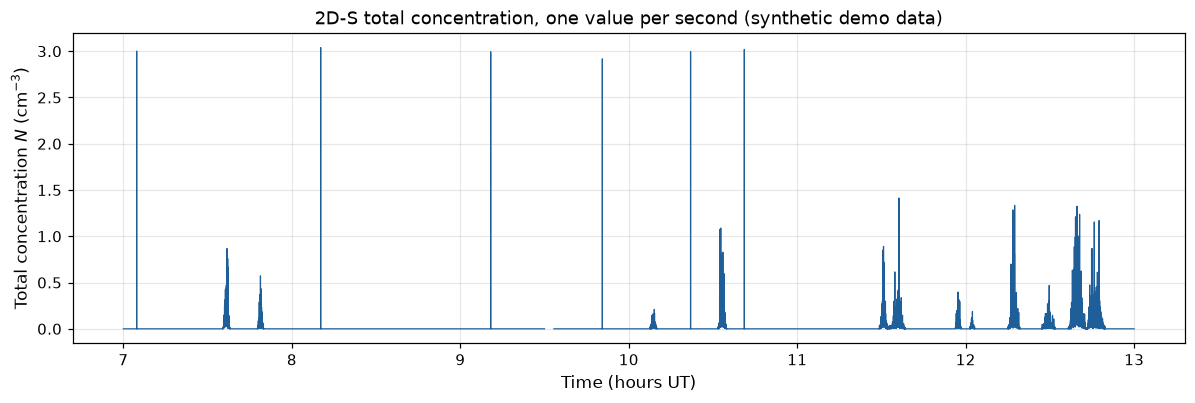

In [7]:
import matplotlib.pyplot as plt
import xarray as xr

with xr.open_dataset(sd_2ds) as ds:
    ds = ds.load()
print(ds)

total_n = ds["n"].values.ravel()
hours_ut = (UT0 + np.arange(total_n.size)) / 3600.0   # one value per second from 07:00 UT
figure, axis = plt.subplots(figsize=(11, 3.8))
axis.plot(hours_ut, total_n, color="#1f5f99", lw=0.8)
axis.set_xlabel("Time (hours UT)", fontsize=11)
axis.set_ylabel("Total concentration $N$ (cm$^{-3}$)", fontsize=11)
axis.set_title("2D-S total concentration, one value per second (synthetic demo data)", fontsize=12)
axis.tick_params(labelsize=10)
axis.grid(alpha=0.3)
figure.tight_layout()
plt.show()

How to read this plot: each point is one second of the synthetic flight. The flat stretches at
zero are clear air between clouds. The handful of tall spikes are short "shattering bursts" put in
by hand (a large ice particle breaking on the probe tip makes a burst of small fragments for a
second or two); section 4 shows what six of them do to a correlation. The short break in the line
is a 200-second stretch where the product holds no data at all (`n` is missing, not zero), which
section 3 keeps apart from the zeros.

## 3. An empty second is a zero, not a gap

`probe_comparison.load_sd` calls `zero_empty_rows`, which turns a NaN bin into a zero wherever that
second's own `n` is finite, and leaves it missing where `n` is NaN. The distinction is not
bookkeeping. Most of a cloud flight is clear air; if those seconds are dropped as missing, each
probe's mean is taken over only the seconds it happened to fill.

The two probes do not fill the same seconds (the smaller sample volume runs out of particles
first), so the two means inflate by **different** factors, and their ratio moves. A ratio that
moves because of how you read a NaN is manufactured, not measured. The cell below measures how far
each mean moves.

In [8]:
"""What reading an empty second as missing would do."""
twods = pc.load_sd([sd_2ds])
cip = pc.load_sd([sd_cip])

for name, side in (("2D-S", twods), ("CIP  ", cip)):
    total = np.nansum(side["nd"], axis=1)
    present = np.isfinite(side["nd"]).any(axis=1)
    as_zeros = float(np.mean(total[present]))
    as_missing = float(np.mean(total[present & (total > 0)]))
    print(f"{name} mean N over the flight: {as_zeros:.5f} cm-3 reading empty seconds as zeros, "
          f"{as_missing:.5f} dropping them (x{as_missing / as_zeros:.1f})")

tot_2ds, tot_cip = np.nansum(twods["nd"], 1), np.nansum(cip["nd"], 1)
both = np.isfinite(twods["nd"]).any(1) & np.isfinite(cip["nd"]).any(1)
r_all = float(np.sum(tot_cip[both]) / np.sum(tot_2ds[both]))
nonzero = both & (tot_2ds > 0) & (tot_cip > 0)
r_nonzero = float(np.sum(tot_cip[nonzero]) / np.sum(tot_2ds[nonzero]))
print(f"\nflight ratio N_CIP / N_2DS over all {int(both.sum())} shared seconds : {r_all:.4f}")
print(f"the same ratio over the {int(nonzero.sum())} seconds both probes filled: {r_nonzero:.4f} "
      f"({r_nonzero / r_all - 1:+.1%})")
print("\nThe second number is not a different measurement of the same thing. It is the first")
print("number plus a selection effect, and the size of the effect is set by which probe ran out")
print("of particles first -- nothing physical.")
print(f"\nthe 200-second gap survives as a gap: n is NaN there, so those seconds are in neither "
      f"mean ({int(np.isfinite(twods['nd']).any(1).sum())} of {N_SECONDS} 2D-S seconds present)")

2D-S mean N over the flight: 0.01107 cm-3 reading empty seconds as zeros, 0.08818 dropping them (x8.0)
CIP   mean N over the flight: 0.00151 cm-3 reading empty seconds as zeros, 0.01368 dropping them (x9.0)

flight ratio N_CIP / N_2DS over all 21400 shared seconds : 0.1379
the same ratio over the 2355 seconds both probes filled: 0.1518 (+10.2%)

The second number is not a different measurement of the same thing. It is the first
number plus a selection effect, and the size of the effect is set by which probe ran out
of particles first -- nothing physical.

the 200-second gap survives as a gap: n is NaN there, so those seconds are in neither mean (21400 of 21600 2D-S seconds present)


## 4. Why a raw Pearson on 1 Hz counts is misleading

`probe_comparison.scatter_stats` returns a Spearman rank correlation and a Pearson correlation of
`log1p` counts, and has no raw-Pearson key at all. The reason is worth seeing rather than being
told.

When most seconds are zero and a few hold hundreds of particles, a Pearson correlation on raw
counts reports the leverage of those few seconds and almost nothing else. A rank statistic, or a
correlation of logarithms, is not held hostage by them.

The cell below shows it on the synthetic pair: the six clear-air shattering seconds of section 2
are six seconds out of more than twenty thousand, and they decide the raw answer.

In [9]:
"""The same seconds, three correlation statistics."""
w2 = pc.rebin_weights(twods["bmin"], twods["bmax"], COMMON)
wc = pc.rebin_weights(cip["bmin"], cip["bmax"], COMMON)
counts_2ds_1hz = pc.row_total(pc.rebin(twods["counts"], w2))
counts_cip_1hz = pc.row_total(pc.rebin(cip["counts"], wc))
shared_ut, x, y = pc.align(twods["ut"], counts_2ds_1hz, cip["ut"], counts_cip_1hz)
finite = np.isfinite(x) & np.isfinite(y)

raw = float(np.corrcoef(x[finite], y[finite])[0, 1])
stats_1hz = pc.scatter_stats(x, y, gate=pc.DEFAULT_COUNT_GATE)
print(f"n = {stats_1hz['n']} seconds, both zero in {stats_1hz['frac_both_zero']:.1%} of them\n")
print(f"  Pearson on raw counts   r = {raw:.3f}   <- never reported")
print(f"  Spearman                r = {stats_1hz['spearman']:.3f}")
print(f"  Pearson on log1p        r = {stats_1hz['pearson_log1p']:.3f}")

order = np.argsort(x[finite])[::-1][:6]
print(f"\nthe six biggest 2D-S seconds hold {x[finite][order].astype(int)} counts")
print(f"the CIP in those same seconds  hold {y[finite][order].astype(int)} counts")
without = finite & ~np.isin(shared_ut, ut[BURST_SECONDS])
trimmed = pc.scatter_stats(np.where(without, x, np.nan), np.where(without, y, np.nan),
                            gate=pc.DEFAULT_COUNT_GATE)
print(f"\nremove those six seconds -- 6 of {int(finite.sum())} -- and the three statistics move:")
print(f"  Pearson on raw counts   {raw:.3f} -> "
      f"{float(np.corrcoef(x[without], y[without])[0, 1]):.3f}")
print(f"  Spearman                {stats_1hz['spearman']:.3f} -> {trimmed['spearman']:.3f}")
print(f"  Pearson on log1p        {stats_1hz['pearson_log1p']:.3f} -> "
      f"{trimmed['pearson_log1p']:.3f}")
print("\nSix seconds in twenty thousand decide the raw Pearson and neither of the other two.")
print("A statistic that a rank transform or a logarithm changes that much was never measuring")
print("the cloud.")

n = 21400 seconds, both zero in 87.6% of them

  Pearson on raw counts   r = 0.321   <- never reported
  Spearman                r = 0.920
  Pearson on log1p        r = 0.886

the six biggest 2D-S seconds hold [1455 1444 1435 1422 1396 1391] counts
the CIP in those same seconds  hold [0 0 0 0 0 0] counts

remove those six seconds -- 6 of 21400 -- and the three statistics move:
  Pearson on raw counts   0.321 -> 0.535
  Spearman                0.920 -> 0.922
  Pearson on log1p        0.886 -> 0.894

Six seconds in twenty thousand decide the raw Pearson and neither of the other two.
A statistic that a rank transform or a logarithm changes that much was never measuring
the cloud.


## 5. One call compares the pair

`probe_comparison.compare_pair(a, b, ...)` takes two products read by `load_sd` and returns a plain
dictionary: the ratio `N_b / N_a` in every common bin with both of its uncertainties, five-minute
window means, the scatter statistics at 1 Hz and on the window means, a coincidence-versus-lag scan
and both size distributions. Here `a` is the 2D-S and `b` the CIP.

`exclude_from_totals=[(55.0, 105.0)]` keeps the smallest common bin in the per-bin table but leaves
it out of every total. The reason is general: the smallest bin of the coarser probe sits near its
resolution limit, where a particle covers only a few pixels and many are missed, so counts there
are not comparable between the two probes. (In this synthetic pair that loss is put in by hand, as
the CIP detection efficiency of section 2.)

The same call works on any two products in the `sizeDist` layout.

In [10]:
"""Compare the pair in one call."""
pair = pc.compare_pair(twods, cip, exclude_from_totals=[(55.0, 105.0)])

print(f"{pair['overlap_seconds']} overlapping seconds, "
      f"{pair['both_finite_seconds']} with both sides finite")
print(f"left out of every total: {pair['excluded_from_totals_um']} um")
coincidence = pair["coincidence"]
print(f"coincidence vs lag peaks at {coincidence['peak_lag_s']:+d} s "
      f"(P = {coincidence['peak_value']:.2f} against an unconditional "
      f"{coincidence['unconditional_b']:.2f}) -- a shared clock, not an offset")

21600 overlapping seconds, 21400 with both sides finite
left out of every total: [[55.0, 105.0]] um
coincidence vs lag peaks at +2 s (P = 0.98 against an unconditional 0.11) -- a shared clock, not an offset


## 6. The band that matters is the edge-shift band, not the Poisson one

This is the single most likely way the comparison misleads. Every ratio `compare_pair` returns
carries two uncertainties, computed together in the same loop:

- **Poisson, 95 %**: `R · exp(±1.96·√(1/C_CIP + 1/C_2DS))`. Over a whole flight the counts are
  large and this is narrow.
- **Edge shift, ±12.5 µm**, the default `edge_shift_um`, a quarter of a bin on the CIP ladder used
  here. The grids share no edge, so shifting the CIP ladder by that much moves a large fraction of
  a bin's particles across a common boundary, and the ratio moves with it.

A ratio plotted with only the Poisson bar looks like a tight measurement of a real difference. It
is not. The cell below prints both widths per common bin and names which one dominates; note
what happens in the last bins, where the counts run out and the honest answer flips.

In [11]:
"""Both uncertainties, per common bin, and which one is larger."""
print(f"{'bin [um]':>12} {'C 2D-S':>9} {'R':>6}   {'Poisson 95%':^22} "
      f"{'+-12.5 um edge shift':^22} dominant")
for row in pair["bins"]:
    ratio = row["R_b_over_a"]
    if ratio is None:
        print(f"{row['bin_um'][0]:6.0f}-{row['bin_um'][1]:5.0f} {row['counts_a']:9.0f}"
              f"      --   no particles in either probe")
        continue
    lo, hi = row["R_ci95"]
    shifted = sorted(v for v in row["R_edge_shift"].values() if v is not None)
    poisson_span, shift_span = hi / lo, shifted[-1] / shifted[0]
    which = "edge shift" if shift_span > poisson_span else "Poisson"
    print(f"{row['bin_um'][0]:6.0f}-{row['bin_um'][1]:5.0f} {row['counts_a']:9.0f} "
          f"{ratio:6.3f}   {lo:6.3f}-{hi:<6.3f} (x{poisson_span:5.2f})  "
          f"{shifted[0]:6.3f}-{shifted[-1]:<6.3f} (x{shift_span:5.2f}) {which}")
print("\nWhere the counts are good the apportioning dominates and the Poisson bar is decoration.")
print("Where the spectrum has run out the Poisson bar takes over -- and a ratio built on four")
print("counts is not a result either way. Both bars have to be on the plot to tell those apart.")

    bin [um]    C 2D-S      R        Poisson 95%        +-12.5 um edge shift  dominant
    55-  105     48137  0.180    0.176-0.183  (x 1.04)   0.153-0.179  (x 1.17) edge shift
   105-  205     26493  0.481    0.472-0.490  (x 1.04)   0.422-0.526  (x 1.25) edge shift
   205-  305      3888  0.824    0.789-0.859  (x 1.09)   0.700-1.018  (x 1.45) edge shift
   305-  405       610  0.903    0.813-1.002  (x 1.23)   0.761-1.178  (x 1.55) edge shift
   405-  505        99  1.010    0.784-1.302  (x 1.66)   0.892-1.297  (x 1.45) Poisson
   505-  605        14  1.463    0.778-2.753  (x 3.54)   1.233-1.694  (x 1.37) Poisson
   605-  705         4  0.944    0.263-3.397  (x12.94)   0.667-1.172  (x 1.76) Poisson
   705-  805         0      --   no particles in either probe
   805-  905         0      --   no particles in either probe
   905- 1005         0      --   no particles in either probe

Where the counts are good the apportioning dominates and the Poisson bar is decoration.
Where the spectru

## 7. Window averaging, and why it needs the density gate

Two probes cannot match second by second, because they sample different volumes; five-minute means
should do better. They do, and they also do something else.

Averaging does two opposite things at once. On the windows where both probes saw cloud it works:
the log-log slope between two independent instruments comes out close to 1:1. Across *all*
windows it can get **worse**, because averaging does not fix a mostly-empty flight: it turns
thousands of noisy seconds into a few dozen windows, most of which still hold no signal, and the
rank statistic is then dominated by ties at zero with far fewer points to work with.

So the density gate (a minimum summed count on each side) is not optional, and it is expensive:
only a fraction of the windows pass it, and the strong number rests on those few points. The cell
below shows both effects on the synthetic pair.

In [12]:
"""The two layers, and what the density gate keeps."""
five_min = pair["windows"]
kept = [b for b in five_min["bins"] if b["kept"]]
s1, s5 = pair["scatter_1hz"], pair["scatter_window"]

print(f"{five_min['window_s']} s windows, a bin kept when >= {five_min['min_cover']} of its "
      f"seconds are finite on both sides")
print(f"  kept  : {len(kept)} of {len(five_min['bins'])} bins")
print(f"  gated : {s5['n_gated']} of those pass the count gate "
      f"{[int(v) for v in pair['count_gate_window']]} (2D-S, CIP summed counts)\n")

print(f"{'':28}{'1 Hz':>12}{'5-minute':>12}")
print(f"{'points':28}{s1['n']:>12}{s5['n']:>12}")
print(f"{'Spearman, all points':28}{s1['spearman']:>12.3f}{s5['spearman']:>12.3f}")
print(f"{'Pearson log1p, all points':28}{s1['pearson_log1p']:>12.3f}{s5['pearson_log1p']:>12.3f}")
print(f"{'Pearson log, dense subset':28}{s1['pearson_log_gated']:>12.3f}"
      f"{s5['pearson_log_gated']:>12.3f}")
print(f"{'RMA slope (log-log)':28}{s1['rma_slope_log10']:>12.3f}{s5['rma_slope_log10']:>12.3f}")
print(f"{'points in that subset':28}{s1['n_gated']:>12}{s5['n_gated']:>12}")

print(f"\nThe 1 Hz layer compares counts, so its ratio of sums ({s1['ratio_of_sums']:.3f}) carries "
      f"the\nsample-volume difference and is not a concentration disagreement. The 5-minute layer")
print("compares mean N, where the volumes have already divided out -- which is why its RMA slope,")
print("and not the 1 Hz one, is the number that can be read as agreement between the probes.")
print(f"\nAnd the cost: the strong statistic rests on {s5['n_gated']} bins.")

300 s windows, a bin kept when >= 270 of its seconds are finite on both sides
  kept  : 71 of 72 bins
  gated : 15 of those pass the count gate [100, 20] (2D-S, CIP summed counts)

                                    1 Hz    5-minute
points                             21400          71
Spearman, all points               0.879       0.816
Pearson log1p, all points          0.852       0.986
Pearson log, dense subset          0.225       0.995
RMA slope (log-log)                1.543       0.965
points in that subset                329          15

The 1 Hz layer compares counts, so its ratio of sums (0.801) carries the
sample-volume difference and is not a concentration disagreement. The 5-minute layer
compares mean N, where the volumes have already divided out -- which is why its RMA slope,
and not the 1 Hz one, is the number that can be read as agreement between the probes.

And the cost: the strong statistic rests on 15 bins.


## 8. The figures

Three panels in one grid, all drawn from the dictionary `compare_pair` returned, so nothing is
recomputed:

- **Size distributions**: both probes' flight-averaged spectra on their own native bins.
- **Ratio per common bin**: the CIP/2D-S ratio with both of its uncertainties.
- **Window-mean scatter**: mean concentration in each five-minute window, 2D-S against CIP.

Remember what you are looking at: invented particles. The shapes are worth reading; the values
are not. First, the shared style: one colour and one display name per probe.

In [13]:
"""Style shared by the three panels."""
import matplotlib as mpl
import matplotlib.pyplot as plt

COLOURS = {"a": "#1f5f99", "b": "#c2571a"}
NAMES = {"a": "2D-S", "b": "CIP"}

Define the first panel: the flight-averaged size distribution of each probe on its own bins.

In [14]:
def draw_size_distributions(ax_sd):
    """Each probe's flight-averaged spectrum on its own native bins."""
    for side, sd in pair["size_distributions"].items():
        mid = np.array(sd["native"]["bin_mid_um"])
        dndd = np.array([np.nan if v is None else v for v in sd["native"]["dNdD_cm3_um"]])
        ax_sd.plot(mid, dndd * 1000.0, color=COLOURS[side], lw=1.6, label=NAMES[side])  # cm-3 -> L-1
    ax_sd.set_xscale("log")
    ax_sd.set_yscale("log")
    ax_sd.set_xlabel("Particle diameter $D$ (µm)", fontsize=11)
    ax_sd.set_ylabel("d$N$/d$D$ (L$^{-1}$ µm$^{-1}$)", fontsize=11)
    ax_sd.set_title("Flight-averaged size distributions", fontsize=12)
    ax_sd.legend(fontsize=10, loc="upper right")

Define the second panel: the ratio of CIP to 2D-S concentration in each common bin, with the Poisson interval and the effect of shifting the bin edges.

In [15]:
def draw_ratio(ax_ratio):
    """The CIP/2D-S ratio in each common bin, with its intervals."""
    for row in pair["bins"]:
        if row["R_b_over_a"] is None:
            continue
        centre = (row["bin_um"][0] + row["bin_um"][1]) / 2.0
        shifted = sorted(v for v in row["R_edge_shift"].values() if v is not None)
        if shifted:
            ax_ratio.plot([centre, centre], [shifted[0], shifted[-1]], color="#c2571a", lw=8,
                          alpha=0.3, solid_capstyle="butt")
        lo, hi = row["R_ci95"]
        ax_ratio.errorbar(centre, row["R_b_over_a"],
                          yerr=[[row["R_b_over_a"] - lo], [hi - row["R_b_over_a"]]],
                          fmt="o", color="#333333", ms=5, capsize=3)
    ax_ratio.plot([], [], color="#c2571a", lw=8, alpha=0.3, label="bin edges shifted ±12.5 µm")
    ax_ratio.plot([], [], "o", color="#333333", label="ratio, 95 % Poisson interval")
    ax_ratio.axhline(1.0, color="grey", lw=1, ls="--")
    ax_ratio.set_xscale("log")
    ax_ratio.set_yscale("log")
    ax_ratio.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))  # 0.2, 1, 2 rather than 2x10^-1
    ax_ratio.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}" if v in (0.2, 0.3, 0.5, 2, 3) else ""))
    ax_ratio.set_xlabel("Common-bin centre diameter (µm)", fontsize=11)
    ax_ratio.set_ylabel("Concentration ratio CIP / 2D-S", fontsize=11)
    ax_ratio.set_title("Ratio in each common bin", fontsize=12)
    ax_ratio.legend(fontsize=10, loc="best")

Define the third panel: mean concentration in each kept five-minute window, 2D-S against CIP, summed over the common bins that count towards totals.

In [16]:
def draw_window_scatter(ax):
    """Five-minute mean concentration, 2D-S against CIP, over the comparable bins."""
    comparable = np.array([row["comparable"] for row in pair["bins"]])
    lo_um = min(row["bin_um"][0] for row in pair["bins"] if row["comparable"])
    hi_um = pair["edges_um"][-1]
    xs, ys = [], []
    for window in pair["windows"]["bins"]:
        if not window.get("kept"):
            continue
        a = np.array([np.nan if v is None else v for v in window["mean_N_a"]])[comparable]
        b = np.array([np.nan if v is None else v for v in window["mean_N_b"]])[comparable]
        xs.append(np.nansum(a) * 1000.0)   # cm-3 -> L-1
        ys.append(np.nansum(b) * 1000.0)
    xs, ys = np.array(xs), np.array(ys)
    drawn = (xs > 0) & (ys > 0)
    ax.scatter(xs[drawn], ys[drawn], s=28, color=COLOURS["a"], alpha=0.8,
               label=f"one five-minute window ({int(drawn.sum())} drawn)")
    low = min(xs[drawn].min(), ys[drawn].min()) / 2
    high = max(xs[drawn].max(), ys[drawn].max()) * 2
    ax.plot([low, high], [low, high], color="grey", ls="--", lw=1, label="1:1 line")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_xlabel(f"2D-S mean concentration, {lo_um:.0f}–{hi_um:.0f} µm (L$^{{-1}}$)", fontsize=11)
    ax.set_ylabel(f"CIP mean concentration, {lo_um:.0f}–{hi_um:.0f} µm (L$^{{-1}}$)", fontsize=11)
    ax.set_title("Five-minute means", fontsize=12)
    ax.legend(fontsize=10, loc="upper left")

Draw the three panels side by side, and print the rank correlation and the log-log slope of the window means.

Spearman r = 0.82; RMA slope (log-log, dense subset of 15 windows) = 0.97   SYNTHETIC -- not a measurement


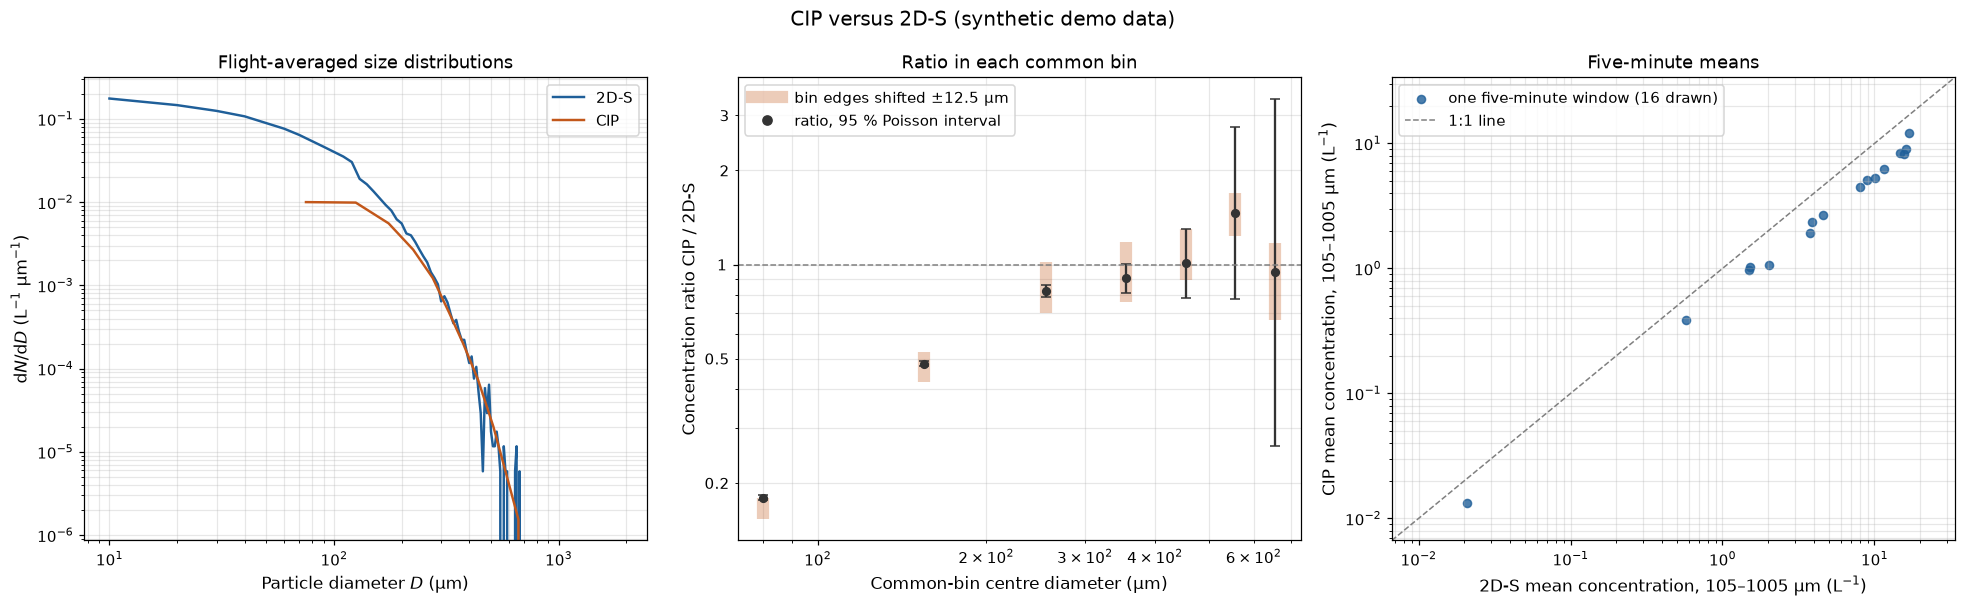

In [17]:
figure, axes = plt.subplots(1, 3, figsize=(18, 5.6))
draw_size_distributions(axes[0])
draw_ratio(axes[1])
draw_window_scatter(axes[2])
for axis in axes:
    axis.tick_params(labelsize=10)
    axis.grid(alpha=0.3, which="both")
figure.suptitle("CIP versus 2D-S (synthetic demo data)", fontsize=13)
figure.tight_layout()
plt.show()
s5 = pair["scatter_window"]
print(f"Spearman r = {s5['spearman']:.2f}; RMA slope (log-log, dense subset of {s5['n_gated']} "
      f"windows) = {s5['rma_slope_log10']:.2f}   SYNTHETIC -- not a measurement")

How to read these figures. In the first panel, both probes see the same falling spectrum; the CIP sits
below the 2D-S at the small end because its larger pixels detect small particles less often (an
efficiency built into the synthetic data). In the middle panel, each dot is the CIP/2D-S ratio in one
common bin with its 95 % counting (Poisson) interval; the wide pale bar behind it is how far the
ratio moves if the CIP bin edges are shifted by ±12.5 µm. Where the pale bar is longer than the
error bar, the regridding, not the counting, sets the uncertainty. The first common bin
(55–105 µm) is left out of the scatter's totals because the two probes are not comparable that
small.

In the third panel, points close to the dashed 1:1 line mean the two probes report the same
concentration over the same five minutes. Windows where either probe recorded nothing cannot be
drawn on log axes and are left out of the plot, though not out of the statistics printed below
it.

## 9. What this shows, and what it cannot

**What it shows.** That two probes with different pixel sizes, different sample volumes and
different bin ladders can be put on one grid and compared once both are in the same product
layout, and that the comparison has four ways of going wrong that are each visible, and each
handled, in `probe_comparison`: the apportioning band, the zero-versus-gap rule, the correlation
statistic, and the density gate.

**What it cannot show.** Anything about either probe or any real flight. Every particle above was
drawn from a random-number generator; the "CIP detection efficiency" and the "shattering bursts"
were put in by hand to make the mechanisms visible. A figure here that looks like a result is a
figure of invented data.

**Using it on your own data.** Point `pc.load_sd` at each probe's `sizeDist` output and call
`pc.compare_pair`; read section 6 before quoting any ratio. A CIP has no archived product
to validate against, so a disagreement with another probe is as likely to be physics as a defect.

**The scratch directory** printed in the set-up cell still holds the two products. Nothing was
written anywhere else in the repository; re-running the notebook builds a fresh directory, and you
can delete this one whenever you like.

In [18]:
"""Where everything landed."""
print("SYNTHETIC DEMONSTRATION -- nothing above is a measurement.\n")
for path in sorted(demo_dir.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(demo_dir).as_posix():<52} {path.stat().st_size // 1024:>6} KiB")
print(f"\nunder <system temp>/{demo_dir.name}")

SYNTHETIC DEMONSTRATION -- nothing above is a measurement.

  sd.synthetic_2ds.nc                                   21941 KiB
  sd.synthetic_cip.nc                                    3544 KiB

under <system temp>/cip_vs_2ds_demo_zxlbs3pp
